# 03 - Inference and Deployment

This notebook demonstrates how the trained MobileNetV2 model is used to classify new chest X-ray images as either Normal or Pneumonia.

In [2]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from PIL import Image

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [ ]:
IMAGE_SIZE = (224,224)
MODEL_PATH = "../models/final_model.keras"
SAMPLE_DIR = "../sample_images"

In [ ]:
model = load_model(MODEL_PATH)
print("Model Loaded Successfully")

Model Loaded Successfully


In [6]:
class_names = {
    0: "NORMAL",
    1: "PNEUMONIA"
}

## Image Preprocessing

In [ ]:
def preprocess_image(image_path):

    img = image.load_img(image_path,target_size=IMAGE_SIZE)

    img_array = image.img_to_array(img)

    img_array = np.expand_dims(img_array,axis=0)

    img_array = preprocess_input(img_array)

    return img,img_array

In [ ]:
def predict_image(image_path):

    img,img_array = preprocess_image(image_path)

    probability = model.predict(img_array,verbose=0)[0][0]

    if probability >= 0.50:
        prediction = "Pneumonia"
        confidence = probability

    else:
        prediction = "Normal"
        confidence = 1-probability

    return (img,prediction,confidence,probability)

## Single Image Prediction

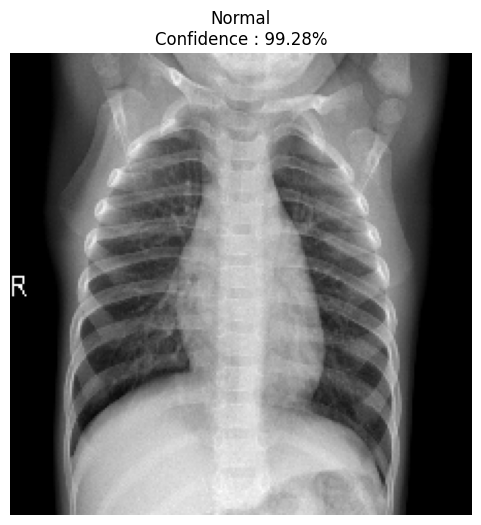

In [ ]:
sample_image = os.path.join(SAMPLE_DIR,os.listdir(SAMPLE_DIR)[0])

img,prediction,confidence,probability = predict_image(sample_image)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"{prediction}\nConfidence : {confidence*100:.2f}%")
plt.show()

## Batch Prediction

In [ ]:
results = []

for file in os.listdir(SAMPLE_DIR):

    if file.lower().endswith((".png",".jpg",".jpeg")):

        path = os.path.join(SAMPLE_DIR,file)

        _,prediction,confidence,_ = predict_image(path)

        results.append({
            "Image":file,
            "Prediction":prediction,
            "Confidence (%)":

                round(confidence*100,2)

        })

results_df = pd.DataFrame(results)

results_df

,Image,Prediction,Confidence (%)
0,NORMAL2-IM-0337-0001.jpeg,Normal,99.279999
1,NORMAL2-IM-0338-0001.jpeg,Pneumonia,62.169998
2,NORMAL2-IM-0339-0001.jpeg,Normal,95.309998
3,NORMAL2-IM-0340-0001.jpeg,Pneumonia,60.410000
4,NORMAL2-IM-0341-0001.jpeg,Normal,99.290001
5,NORMAL2-IM-0343-0001.jpeg,Normal,90.449997
6,person1_virus_11.jpeg,Pneumonia,99.300003
7,person1_virus_12.jpeg,Pneumonia,99.919998
8,person1_virus_6.jpeg,Pneumonia,99.599998
9,person1_virus_7.jpeg,Pneumonia,99.650002


In [11]:
results_df["Prediction"].value_counts()

Prediction
Pneumonia    8
Normal       4
Name: count, dtype: int64

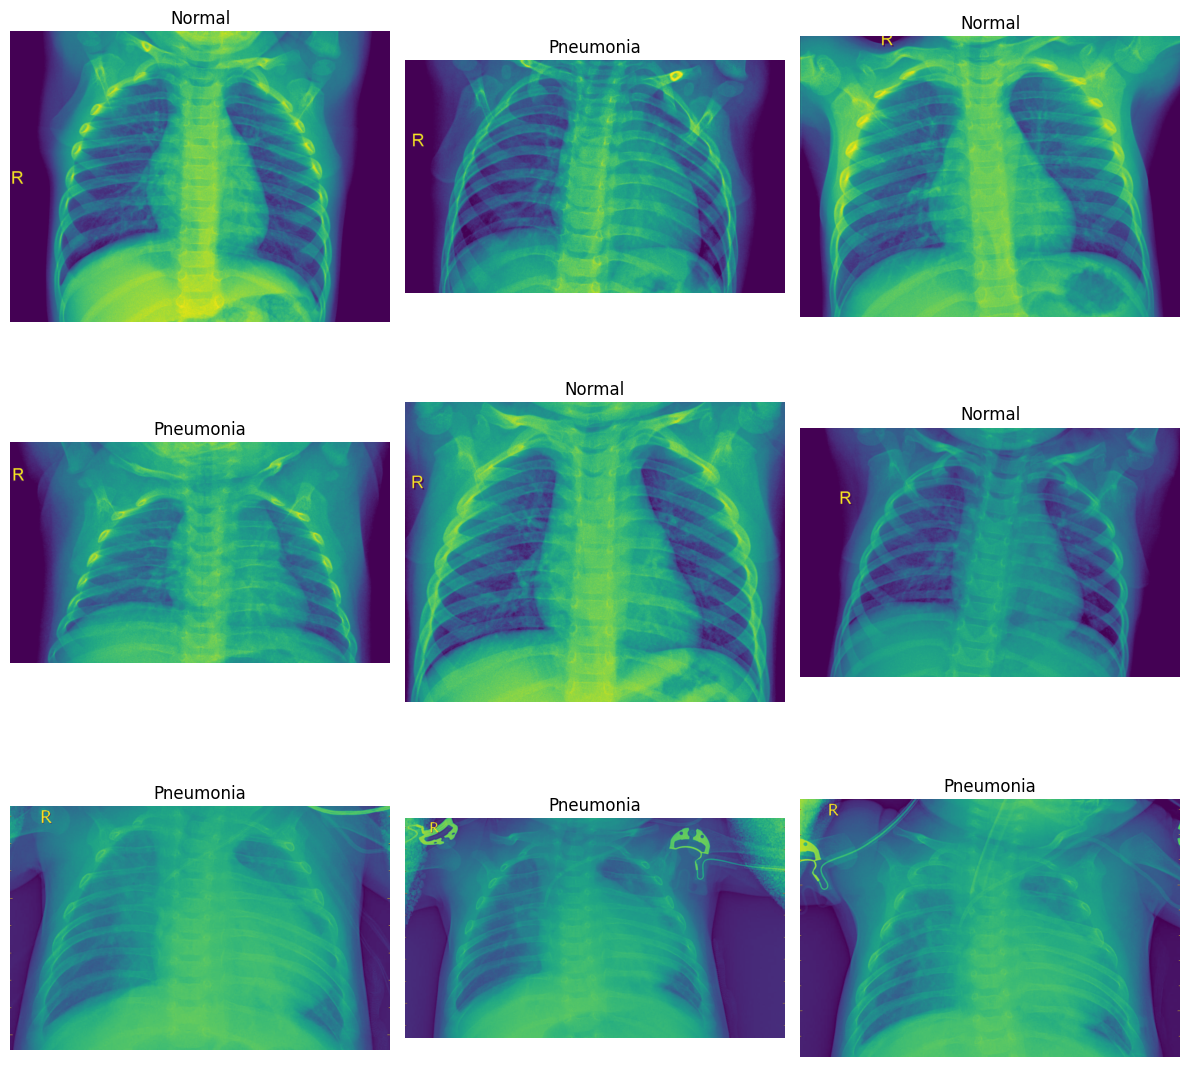

In [ ]:
num_images = min(len(results_df),9)

plt.figure(figsize=(12,12))

for i,file in enumerate(results_df["Image"][:num_images]):

    path = os.path.join(SAMPLE_DIR,file)
    img = Image.open(path)

    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(results_df.loc[i,"Prediction"])

plt.tight_layout()
plt.show()